# 0-30Y FedWatch Engine — Dashboard

Unified rates curve & probability engine replacing `ffrsdetailed.ipynb`.

| Segment | Horizon | Products | Method |
|---|---|---|---|
| Regime 1 | 0-18M | `ZQ` 30D Fed Funds (+`SR1`) | FOMC day-weighted step probabilities (CME FedWatch parity) |
| Regime 2 | 18M-3Y | `SR3` 3M SOFR futures | Hull-White convexity-adjusted OIS forwards |
| Regime 3 | 3-30Y | Eris SOFR swap futures (`YI*`) | price -> par swap inversion, sequential bootstrap |

Single SOFR-discounting curve via Hagan-West monotone convex forwards.
**Phase 1**: probabilities beyond FOMC horizons are model-based (historical-vol +
Hull-White). **Phase 2** (stubbed): SR3/Treasury options -> SABR -> Breeden-Litzenberger PDFs.

Run all cells top-to-bottom. Set `ASOF = None` for the latest data date.


In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from fedwatch import pipeline as pl
from fedwatch import regime1_fomc as r1
from fedwatch import diagnostics as dg
from fedwatch import densities as dn
from fedwatch import backtest as bt
from fedwatch import plotting as fp

pd.set_option('display.width', 220)
ASOF = None            # e.g. '2026-11-20'; None = latest
REFRESH = False        # True -> pull fresh Databento/FRED/Eris data (~$0.30/day)

In [2]:
# === MANUAL DATA REFRESH ============================================
# POLICY: no automatic/scheduled pulls. Run THIS cell only when you want
# new data. Cost ~ $0.10 + ~$0.15 x days-since-last-pull.
from fedwatch.refresh import refresh_all
summary = refresh_all(refresh_fomc=True)   # add include_eris_history=True rarely (54MB)


pull ['ZQ', 'SR1', 'SR3', 'ZT', 'ZF', 'ZN', 'ZB', 'TN', 'YIA', 'YIT', 'YIC', 'YID', 'YIW', 'YIB', 'YIY', 'YII', 'YIL', 'YIO', 'YIE'] ohlcv-1d 2026-11-21 -> 2026-11-24: $0.01


/Users/Saurbier/Desktop/FFR-futures/fedwatch/ingest/databento_io.py:110: BentoWarning: The streaming request contained one or more days which have reduced quality: 2026-11-22 (degraded). See: https://databento.com/docs/api-reference-historical/metadata/metadata-get-dataset-condition
  res = cli.timeseries.get_range(


/Users/Saurbier/Desktop/FFR-futures/.venv/lib/python3.12/site-packages/databento/common/dbnstore.py:1538: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index(index_column, inplace=True)


/Users/Saurbier/Desktop/FFR-futures/fedwatch/ingest/databento_io.py:110: BentoWarning: The streaming request contained one or more days which have reduced quality: 2026-11-22 (degraded). See: https://databento.com/docs/api-reference-historical/metadata/metadata-get-dataset-condition
  res = cli.timeseries.get_range(


/Users/Saurbier/Desktop/FFR-futures/.venv/lib/python3.12/site-packages/databento/common/dbnstore.py:1538: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index(index_column, inplace=True)


/Users/Saurbier/Desktop/FFR-futures/fedwatch/ingest/databento_io.py:110: BentoWarning: The streaming request contained one or more days which have reduced quality: 2026-11-22 (degraded). See: https://databento.com/docs/api-reference-historical/metadata/metadata-get-dataset-condition
  res = cli.timeseries.get_range(


... (31 outputs left out)

/Users/Saurbier/Desktop/FFR-futures/fedwatch/ingest/databento_io.py:110: BentoWarning: No data found for the request you submitted.
  res = cli.timeseries.get_range(
/Users/Saurbier/Desktop/FFR-futures/fedwatch/ingest/databento_io.py:110: BentoWarning: The streaming request contained one or more days which have reduced quality: 2026-11-22 (degraded). See: https://databento.com/docs/api-reference-historical/metadata/metadata-get-dataset-condition
  res = cli.timeseries.get_range(


/Users/Saurbier/Desktop/FFR-futures/.venv/lib/python3.12/site-packages/databento/common/dbnstore.py:1538: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index(index_column, inplace=True)


futures cache: 201,975 rows, 2010-06-06 -> 2026-11-23, 2028 contracts


  futures        2026-11-23 (201,975 rows)
  fred           2026-11-24
  eris           instruments settles + parcurve refreshed
  sr3_options    SR3: no new data pulled
  ozf_options    OZF: no new data pulled
  ozn_options    OZN: no new data pulled
  ozb_options    OZB: no new data pulled
  fomc           216 meetings -> 2027-11-17


In [3]:
# --- data + curve (one call: SR1 bridge -> SR3 quarters -> Eris long end)
res = pl.run(refresh=REFRESH, asof=ASOF)
asof = res['asof']
print(f"as-of {asof.date()} | {len(res['curve'].dates)} curve nodes -> {res['curve'].dates[-1].date()}")

as-of 2026-11-23 | 24 curve nodes -> 2056-12-20


In [4]:
# --- Regime 1: FOMC meeting probabilities (FedWatch parity)
recs = r1.fomc_probabilities(res['bundle']['fut'], res['bundle']['fred'], res['bundle']['fomc'])
path = r1.expected_path(recs, asof)
print(path.to_string(index=False, float_format=lambda v: f'{v:8.2f}'))

meeting_date  target_after_bps   p_hike    p_cut   p_hold  exp_steps
  2026-12-09            414.77     1.00     0.00     0.00       1.07
  2027-01-27            428.16     1.00     0.00     0.00       0.54
  2027-03-17            443.66     1.00     0.00     0.00       0.62
  2027-04-28            428.66     0.90     0.00     0.10      -0.60
  2027-06-09            435.09     0.93     0.00     0.07       0.26
  2027-07-28            435.83     0.93     0.00     0.07       0.03
  2027-09-15            436.83     0.93     0.00     0.07       0.04
  2027-10-27            432.95     0.89     0.01     0.10      -0.15
  2027-11-17            434.97     0.90     0.01     0.09       0.08


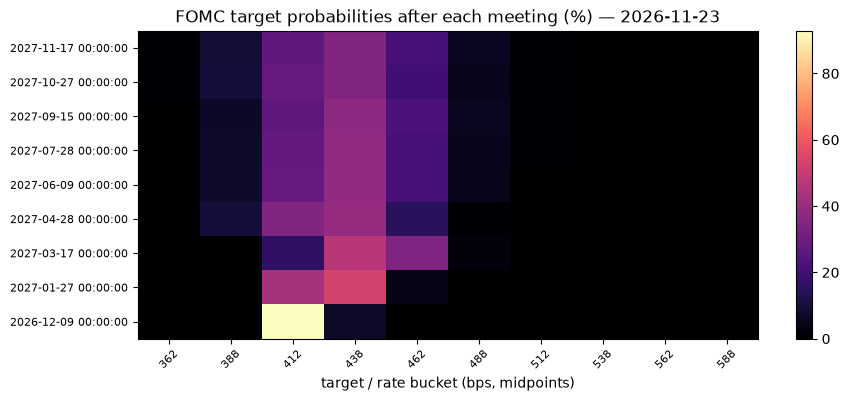

In [5]:
# --- FedWatch-style probability matrix per meeting (%, 25bp buckets)
mat = r1.meeting_matrix(recs, asof)
(fp.plot_probability_heatmap(mat, title=f'FOMC target probabilities after each meeting (%) — {asof.date()}'),)
plt.gcf().set_size_inches(10, 4); plt.colorbar(plt.gca().images[0]); plt.show()

In [6]:
# --- verification suite (must all pass)
print(dg.check_curve(res).to_string(index=False))
print(dg.check_probabilities(recs, asof).to_string(index=False))

                  check  pass                                                                                 detail
     forward positivity  True                                                                    min inst-fwd 3.646%
  front segment present  True                                       6 nodes in first 15M (SR1 bridge + SR3 quarters)
SR3 quarterly repricing  True                                                     max |gap| 0.247bp over 13 quarters
  Eris published parity  True 4Y -0.51bp; 5Y -0.92bp; 7Y -0.42bp; 10Y -0.05bp; 15Y -0.22bp; 20Y -0.62bp; 30Y -2.52bp
   SR3/Eris seam (>=2Y) False                                                  1Y -11.85bp; 2Y -10.88bp; 3Y -10.64bp
                  check  pass                           detail
FOMC probability sanity  True 9 meetings, max |mass-1| 2.2e-16


In [7]:
# --- cross-product diagnostics: SR3<->Eris seam + published-par parity
print('seam (Eris implied vs SR3-segment curve):')
print(res['seam'].round(2).to_string(index=False))
pc = res['bundle']['eris_parcurve'].asof(asof)
ev = res['eris_eval'].set_index('tenor_years')['par_rate_bps']
print('\nEris tenor parity vs their published par curve (bps):')
for t, col in [(4,'SOFR4Y'),(5,'SOFR5Y'),(7,'SOFR7Y'),(10,'SOFR10Y'),(15,'SOFR15Y'),(20,'SOFR20Y'),(30,'SOFR30Y')]:
    if t in ev.index: print(f'  {t:>2.0f}Y  ours {ev[t]:7.2f}  published {pc[col]*100:7.2f}  diff {ev[t]-pc[col]*100:+5.2f}')

seam (Eris implied vs SR3-segment curve):
 tenor_years  zcode  effective  eris_implied_bps  sr3_curve_bps  gap_bps
         1.0 YIAZ26 2026-12-16            447.92         459.78   -11.85
         2.0 YITZ26 2026-12-16            446.30         457.18   -10.88
         3.0 YICZ26 2026-12-16            442.65         453.29   -10.64

Eris tenor parity vs their published par curve (bps):
   4Y  ours  440.28  published  440.78  diff -0.51
   5Y  ours  439.73  published  440.65  diff -0.92
   7Y  ours  443.16  published  443.57  diff -0.42
  10Y  ours  451.42  published  451.48  diff -0.05
  15Y  ours  464.94  published  465.16  diff -0.22
  20Y  ours  470.38  published  470.99  diff -0.62
  30Y  ours  462.59  published  465.12  diff -2.52


In [8]:
# --- unified master matrix: FOMC meetings + model-based tenor densities
mm = pl.master_matrix(res, recs)
print(f'{mm.shape[0]} buckets x {mm.shape[1]} horizons; col sums:')
print(mm.sum(axis=0).round(4).to_string())

44 buckets x 17 horizons; col sums:
2026-12-09     1.0
2027-01-27     1.0
2027-03-17     1.0
2027-04-28     1.0
2027-06-09     1.0
2027-07-28     1.0
2027-09-15     1.0
2027-10-27     1.0
2027-11-17     1.0
2Y (model)     1.0
3Y (model)     1.0
5Y (model)     1.0
7Y (model)     1.0
10Y (model)    1.0
15Y (model)    1.0
20Y (model)    1.0
30Y (model)    1.0


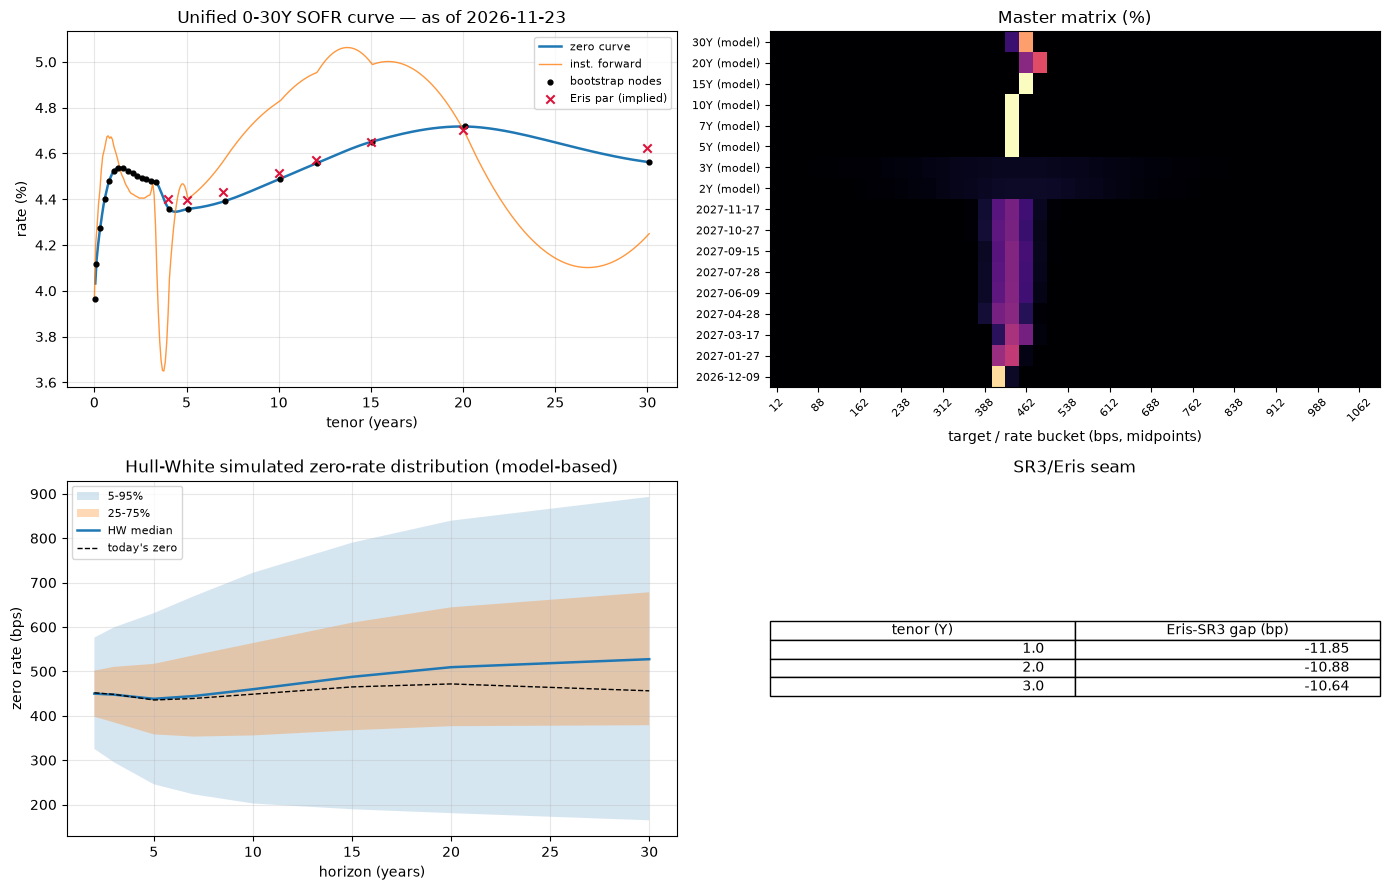

In [9]:
# --- curve + densities dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fp.plot_curve(res, ax=axes[0, 0])
fp.plot_probability_heatmap(mm.T, ax=axes[0, 1], title='Master matrix (%)')
fan = dn.hw_simulate(res['curve'], sigma=0.0095)
fp.plot_hw_fan(fan, res['curve'], asof, ax=axes[1, 0])
axes[1, 1].axis('off')
seam = res['seam']
axes[1, 1].table(cellText=[[r.tenor_years, round(r.gap_bps, 2)] for r in seam.itertuples()],
                 colLabels=['tenor (Y)', 'Eris-SR3 gap (bp)'], loc='center')
axes[1, 1].set_title('SR3/Eris seam')
plt.tight_layout(); plt.show()

In [10]:
# --- historical calibration of the FOMC engine
print(bt.backtest(recs, res['bundle']['fred']).to_string())

            hit_rate  avg_p_realized      n
dtm                                        
(0, 7]         0.778           0.727    576
(7, 14]        0.778           0.731    581
(14, 30]       0.757           0.700   1308
(30, 90]       0.670           0.600   4700
(90, 180]      0.572           0.475   6886
(180, 400]     0.361           0.275  15586


In [11]:
# --- Phase 2: option-implied densities (SR3 options -> SABR -> BL PDFs)
from fedwatch import phase2 as p2
from fedwatch import diagnostics as dg2

opt = p2.load_options()
chains, fits = p2.option_snapshots(res['bundle']['fut'], asof, opt=opt)
print(f"{len(chains)} chains, {len(fits)} SABR fits")
print(fits[['underlying','expiry','horizon_years','atm_vol_bp','rmse_bp','n_quotes']]
      .round(2).to_string(index=False))

13 chains, 12 SABR fits
underlying     expiry  horizon_years  atm_vol_bp  rmse_bp  n_quotes
     SR3Z6 2026-12-16           0.06       20.85    16.33        22
     SR3F7 2027-01-20           0.16       84.46    34.56        15
     SR3G7 2027-02-17           0.24       99.83    13.11        10
     SR3H7 2027-03-17           0.31       80.99     8.86        20
     SR3J7 2027-04-21           0.41      109.00    10.94        13
     SR3M7 2027-06-16           0.56      105.48    15.14        24
     SR3U7 2027-09-15           0.81      119.40     7.33        17
     SR3Z7 2027-12-15           1.06      131.98     7.20        23
     SR3H8 2028-03-15           1.31      120.64     5.69        11
     SR3M8 2028-06-21           1.58      124.93    14.20         5
     SR3U8 2028-09-20           1.83      120.74     4.26         6
     SR3Z8 2028-12-20           2.08      124.00     6.26         7


/var/folders/hm/36htpvln1h7d8k8hnh40nt4h0000gn/T/ipykernel_34633/4026483701.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2).to_string(index=False))


In [12]:
# --- option-implied PDFs -> 25bp buckets, merged into the master matrix
opt_cols, opt_check = p2.option_density_columns(fits, res['bundle']['fut'], asof, opt=opt)
print("martingale check (PDF mean vs forward):")
print(opt_check[['underlying','horizon_years','atm_vol_bp','mean_gap_bp']].round(2).to_string(index=False))
mm2 = p2.merge_into_master(mm, opt_cols)
print(f"\nmaster matrix now {mm2.shape[1]} horizons; option columns:",
      [c for c in mm2.columns if '(option)' in c])
print(dg2.check_options(fits, opt_check).to_string(index=False))

martingale check (PDF mean vs forward):
underlying  horizon_years  atm_vol_bp  mean_gap_bp
     SR3Z6           0.06       20.85         0.17
     SR3G7           0.24       99.83         0.54
     SR3H7           0.31       80.99         0.96
     SR3J7           0.41      109.00        -0.75
     SR3M7           0.56      105.48         5.95
     SR3U7           0.81      119.40         2.71
     SR3Z7           1.06      131.98         7.48
     SR3H8           1.31      120.64         4.82
     SR3U8           1.83      120.74        -0.06
     SR3Z8           2.08      124.00         2.68

master matrix now 27 horizons; option columns: ['2026-12-16 (option)', '2027-02-17 (option)', '2027-03-17 (option)', '2027-04-21 (option)', '2027-06-16 (option)', '2027-09-15 (option)', '2027-12-15 (option)', '2028-03-15 (option)', '2028-09-20 (option)', '2028-12-20 (option)']
                   check  pass                               detail
     option fits present  True 12 expiries fit, hori

In [13]:
# --- ATM normal vol term structure -> Regime-2 convexity sigma
from fedwatch.regime2_sr3 import estimate_hw_sigma_from_options
sig_opt = estimate_hw_sigma_from_options(res['bundle']['fut'], asof, opt=opt)
sig_hist = res['sr3_strip'].attrs.get('hw_sigma')
print(f"HW sigma: options-implied {sig_opt*1e4 if sig_opt else float('nan'):.1f}bp "
      f"vs historical proxy {sig_hist*1e4:.1f}bp")
print(p2.atm_vol_term_structure(fits).round(1).to_string())

HW sigma: options-implied 96.6bp vs historical proxy 96.3bp
horizon_years
0.063014     20.9
0.158904     84.5
0.235616     99.8
0.312329     81.0
0.408219    109.0
0.561644    105.5
0.810959    119.4
1.060274    132.0
1.309589    120.6
1.578082    124.9
1.827397    120.7
2.076712    124.0


In [14]:
# --- Phase 3: Treasury futures options -> 5Y/10Y/30Y UST yield densities
from fedwatch import treasury_options as topt
from fedwatch import diagnostics as dg3

ust_cols, ust_check = topt.treasury_density_columns(res, asof)
print("UST option chains:")
print(ust_check[['chain','tenor','n_quotes','atm_vol_pts','atm_vol_yield_bp','y_ref_pct']]
      .round(3).to_string(index=False))
print(dg3.check_treasury(ust_check, asof).to_string(index=False))

UST option chains:
          chain  tenor  n_quotes  atm_vol_pts  atm_vol_yield_bp  y_ref_pct
ZBH7|2027-02-19     30        32       12.329            70.450      5.285
ZFH7|2027-02-19      5        37        4.753           108.028      4.701
ZNH7|2027-02-19     10        29        7.003            80.498      4.919
                  check  pass                                                                    detail
UST option fits present  True 3 chains, tenors [np.int64(5), np.int64(10), np.int64(30)], horizon 0.24Y
    ATM yield vols sane  True                                                    70-108bp across chains
  SABR price-space rmse  True                                            max 0.455pts (7.9% of ATM vol)


In [15]:
# --- merged view: SOFR options (<=2Y) + UST yields (5-30Y) + FOMC + models
mm3 = p2.merge_into_master(mm2, ust_cols)
print(f"master matrix: {mm3.shape[0]} buckets x {mm3.shape[1]} horizons")
print("option-implied columns:", [c for c in mm3.columns if '(option' in c])

master matrix: 44 buckets x 30 horizons
option-implied columns: ['2026-12-16 (option)', '2027-02-17 (option)', '2027-03-17 (option)', '2027-04-21 (option)', '2027-06-16 (option)', '2027-09-15 (option)', '2027-12-15 (option)', '2028-03-15 (option)', '2028-09-20 (option)', '2028-12-20 (option)', '2027-02-19 UST30Y (option)', '2027-02-19 UST5Y (option)', '2027-02-19 UST10Y (option)']


## Phase 3 — Treasury options for the long end (shipped)

OZF/OZN/OZB (5Y/10Y/30Y note & bond futures options, GLBX `OZ*.OPT`) →
OTM-filtered chains → Normal SABR in price space → BL price density →
yield-space mapping via constant dollar duration (v1: ZF 4.4, ZN 8.7, ZB 17.5
pts per 1.00 of yield; CTD tables are the v2 upgrade) → anchored at the
forward Treasury yield (Eris forward par minus standing swap spread) →
25bp buckets labelled `(option, UST…)`.

Notes: these are Treasury-yield distributions (swap-spread-anchored), the
5Y+ analogue of the SOFR option PDFs; American-exercise distortion is
minimised by the OTM-only filter.